# Projekt 1 - kotki i kwiaty - Tymoteusz Bultrowicz - tb469198

### Setup
Notatnik przystosowany jest do świeżego środowiska Google Colab. Kod w trzech komórkach poniżej pobiera i importuje biblioteki.

**Ważne !** Z racji braku kompatybilności numpy 2.0 ze scikit-learn-extra, napisany poniżej setup_enviroment() często wymusza restart środowiska. Po połączeniu się ponownie konflikt zostanie rozwiązany.

**Ważne 2!** Kod nie pobiera automatycznie folderu danych ze zdjęciami. Wczyta go ze względnej ścieżki PHOTO_PATH podanej poniżej, wymaga zachowania oryginalnych nazw i ilości zdjęć.

In [ ]:
import os
def setup_enviroment():
  try:
    import numpy as np
    if int(np.__version__.split('.')[0]) >= 2:
      return True
    import sklearn_extra
    import optuna
  
  except ImportError:
    return True

if setup_enviroment():
  !pip uninstall -y numpy
  !pip install "numpy<2" scikit-learn-extra optuna
  os.kill(os.getpid(), 9)

In [2]:
PHOTO_PATH = "photos"

In [3]:
import colorsys
import os
import pandas as pd
import numpy as np
import plotly.express as px
from PIL import Image
from IPython.display import display

# Constants for sizes of photos' kinds in dataset.
LEN_KITT = 55
LEN_FLOW = 77
IMAGE_SIZE = 100

## Zadanie 1

### Zaczynamy od stworzenia bazy danych wszystkich pikseli, pobierając je z naszych fotografii. 

Na potrzeby dalszej analizy poza RGB i HLS dodajemy kolumny ["R_bin", "G_bin", "B_bin"], które przypisują pikselowi kolor z zawężonej palety barw.

In [4]:
def acc_pixels(pixels, photo, isKitty, photoNum):
    for x in range(photo.width):
        for y in range(photo.height):
            r, g, b = photo.getpixel((x, y))
            h, l, s = colorsys.rgb_to_hls(r / 255.0, g / 255.0, b / 255.0)
            pixels.append([isKitty, photoNum, x, y, r, g, b, h * 360, s, l])

def get_pixels(folder_path):
    DEGREES = 360
    pixels = []
    lens = [LEN_KITT, LEN_FLOW]
    names = ["kotek", "kwiatek"]
    for j in range(2):
        for i in range(lens[j]):
            image_path = os.path.join(folder_path, f"{names[j]}-{i}.png")
            image = Image.open(image_path).convert("RGB")
            acc_pixels(pixels, image, (j == 0), i)

    return pd.DataFrame(pixels, columns=["IsKitty", "Photo", "X", "Y", "R", "G", "B", "H", "S", "L"])

pixels_df = get_pixels(PHOTO_PATH)
# Narrowing possible colors from 256x256x256 set to 16x16x16 set.
pixels_df[["R_bin", "G_bin", "B_bin"]] = (pixels_df[["R", "G", "B"]] // 16) * 16 + 8

Testujemy poprawność naszej bazy danych, rekonstruując zdjęcie jednego kotka.

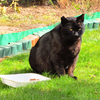

In [5]:
def print_kitty_picture(pixels_df, image_num):
    image_pixels = pixels_df[(pixels_df["Photo"] == image_num) & (pixels_df["IsKitty"])].copy()
    image_pixels = image_pixels.sort_values(by=["Y", "X"])
    image = Image.fromarray(image_pixels[["R", "G", "B"]].values.reshape(IMAGE_SIZE, IMAGE_SIZE, 3).astype(np.uint8))
    display(image)

print_kitty_picture(pixels_df, 49)

### Tworzymy bazę danych analizującą częstotliwość wystąpień pikseli na zdjęciach, szukamy dominujących barw i odcieni.

Zdecydowałem się na korzystanie z zawężonego zbioru barw, ponieważ przy pełnej gamie barw pojedyncze kolory są dzielone na tysiace odcieni, co utrudnia sensowną analizę wystąpień kolorów -> Bez tej zmiany wykres scatter miliona kolorów się nie renderował, a pewnej próby kolorów nie dawał interpretowalnych wyników. Ponadto analiza najczęstszych kolorów była nieciekawa, przeważały skrajnie czarne i białe kolory..

Oczywiście liczba unikatowych kolorów oraz wartości binarne zliczane są po oryginalnych barwach.

In [6]:
def analyze(pixels_df, by_bins=True):
  df = pixels_df.groupby(["R_bin", "G_bin", "B_bin"] if by_bins else ["R", "G", "B"]).agg(
      InKitties=("IsKitty", "sum"),
      InFlowers=("IsKitty", lambda x: len(x) - sum(x)),
  ).reset_index()
  if by_bins:
    df = df.rename(columns={"R_bin" : "R", "G_bin" : "G", "B_bin" : "B"})

  tmp = df[["R", "G", "B"]] / 255.0
  df[["H", "L", "S"]] = [colorsys.rgb_to_hls(*row) for row in tmp.values]
  df["H"] = df["H"] * 360

  df["IsCold"] = df["H"].map(lambda h: h >= 180 and h <= 270)
  df["IsSaturated"] = df["S"].map(lambda s: s >= 0.7)

  max_vals = df[["R", "G", "B"]].max(axis = 1)
  for color in ["R", "G", "B"]:
      df[f"{color}Strongest"] = (df[color] == max_vals)
  df = df.drop(columns=["H", "L", "S"])

  return df

analyze_df = analyze(pixels_df, True)

## Zadanie 2

Szukamy zależności definiujących obiekty w naszym zbiorze danych, zliczamy ilość unikatowych kolorów na pojedynczych zdjęciach.

In [7]:
pix_count_df = pixels_df.drop_duplicates(subset=["IsKitty", "Photo", "R", "G", "B"])
pix_count_df = pix_count_df.groupby(["IsKitty", "Photo"]).size().reset_index(name="PixelCount")
print("Numbers of unique pixels on photos: \n")
print(pix_count_df["PixelCount"].describe())

print("\n\nTop colors analysis:")
def print_color_square(r, g, b):
    print(f"\033[48;2;{r};{g};{b}m  \033[0m", end="")

top_cat_cols = analyze_df.nlargest(5, "InKitties")[["R", "G", "B", "InKitties"]]
top_flower_cols = analyze_df.nlargest(5, "InFlowers")[["R", "G", "B", "InFlowers"]]
print("Top 5 colors in Kitties:")
for _, row in top_cat_cols.iterrows():
    print_color_square(row["R"], row["G"], row["B"])
    print (f" - {row['InKitties']} occurences")
print("\nTop 5 colors in Flowers:")
for _, row in top_flower_cols.iterrows():
    print_color_square(row["R"], row["G"], row["B"])
    print (f" - {row['InFlowers']} occurences")

print("\n\n\nSaturation and Lightness Analysis:")
sat_desc_cat = pixels_df[pixels_df["IsKitty"]]["S"].describe()
sat_desc_flower = pixels_df[~pixels_df["IsKitty"]]["S"].describe()
ligth_desc_cat = pixels_df[pixels_df["IsKitty"]]["L"].describe()
ligth_desc_flower = pixels_df[~pixels_df["IsKitty"]]["L"].describe()

print("Saturation in Kitties:\n", sat_desc_cat)
print("\nSaturation in Flowers:\n", sat_desc_flower)
print("\nLightness in Kitties:\n", ligth_desc_cat)
print("\nLightness in Flowers:\n", ligth_desc_flower)

Numbers of unique pixels on photos: 

count     132.000000
mean     8649.393939
std      1163.402865
min      4538.000000
25%      7988.000000
50%      9072.500000
75%      9521.250000
max      9911.000000
Name: PixelCount, dtype: float64


Top colors analysis:
Top 5 colors in Kitties:
   - 7165 occurences
   - 6478 occurences
   - 5339 occurences
   - 5187 occurences
   - 4847 occurences

Top 5 colors in Flowers:
   - 35108 occurences
   - 22004 occurences
   - 14189 occurences
   - 14088 occurences
   - 11883 occurences



Saturation and Lightness Analysis:
Saturation in Kitties:
 count    550000.000000
mean          0.318067
std           0.216971
min           0.000000
25%           0.142857
50%           0.281553
75%           0.450704
max           1.000000
Name: S, dtype: float64

Saturation in Flowers:
 count    770000.000000
mean          0.468028
std           0.296100
min           0.000000
25%           0.228070
50%           0.401274
75%           0.720000
max           1.

### Wnioski z analizy rozkładów wartości:

1. Najważniejszym wnioskiem jest olbrzymia gama kolorów występująca na zdjęciach. Średni 10e5 pikselowy obrazek posiada 8649 różnych kolorów, więc prawie każdy piksel to inny kolor. Nawet dla najbardziej jednolitego obrazu 4538 różnych kolorów daje stosunek bliski 2:1 pikseli do kolorów.

2. Nierównomierność wystąpień kolorów - Mimo, że na każdym zdjęciu mamy sporo unikatowych pikseli, istnieją grupy wielu pikseli wpadające w ten sam kolor. Zdecydowanie częściej od reszty występuje przede wszystkim kolor czarny. Poza nim dla kotów są to odcienie szarości, a dla kwiatów ciemne odcienie ziemne, szary oraz zielony.

3. Różnice między zbiorami - Poza tą napisaną w punkcie 2, widzimy że zdjęcia kotów są zauważalnie mniej nasycone oraz lekko jaśniejsze. Rozkład ogonów jest bardzo podobny dla każdego zbioru i każdej wartości - w każdy mze zbiorów piksele zapełniąją pełną gamę przedziału [0,1].

Poszukajmy dalszych różnic tworząc odpowiednie wykresy:

In [8]:
def plot_stacked_analysis(analysis_df, binary_var, name):
  agg_df = analysis_df.groupby(binary_var)[["InKitties", "InFlowers"]].sum().reset_index()
  long_df = agg_df.melt(
      id_vars=binary_var,
      value_vars=["InKitties", "InFlowers"],
      var_name="Baza",
      value_name="LiczbaPikseli"
  )

  fig = px.bar(
      long_df,
      x="Baza",
      y="LiczbaPikseli",
      color=binary_var,
      title=f"Skumulowany rozkład cechy: {name}",
      labels={"LiczbaPikseli": "Suma pikseli", "Baza": "Zbiór zdjęć"},
  )
  fig.update_layout(showlegend=True)
  fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
  fig.show()

analyze_df["rgbColumn"] = ("rgb(" + analyze_df["R"].astype(str) + "," +
            analyze_df["G"].astype(str) + "," + analyze_df["B"].astype(str) + ")")

print("Uniqe color distribution per image:\n")
fig = px.histogram(pix_count_df, x="PixelCount", color="IsKitty", nbins=22,
                    title="Rozkład liczby unikalnych kolorów na zdjęciach")
fig.show()

print("Color Distribution Analysis:\n")
fig = px.scatter(
    analyze_df,
    x="InKitties", y="InFlowers",
    log_x=True, log_y=True,
    color="rgbColumn",
    color_discrete_map="identity",
    title="Rozkład kolorów w kotkach i kwiatach - skala logarytmiczna:",
)
up_to = analyze_df["InFlowers"].max()

# Adding reference line for equal distribution, scaled by dataset sizes,
# so that we can compare frequencies of colors appearence in both categories.
fig.add_scatter(x=[0, up_to * LEN_KITT / LEN_FLOW], y=[0, up_to], showlegend=False)
fig.show()
analyze_df = analyze_df.drop(columns=["rgbColumn"])

print("Individual traits analysis:\n")
plot_stacked_analysis(analyze_df, binary_var="IsSaturated", name="Saturacja")
plot_stacked_analysis(analyze_df, binary_var="GStrongest", name="Dominacja zieleni")
plot_stacked_analysis(analyze_df, binary_var="RStrongest", name="Dominacja czerwieni")

Uniqe color distribution per image:



Color Distribution Analysis:



Individual traits analysis:



### Różnice zbiorów c.d. :

1. Rozkład kolorów - Bardzo widoczny na wykresie rozrzutu. Dla zdjęć kotów, jako że pozują na tle trawy, zielone bary występują znacznie częściej. Z kolei w kwiatach dominują barwy żółte/czerwone/różowe, jako że zdjęcia kwiatów są na nie zbliżone. Potwierdzają to dodatkowo wykresy dominacji koloru zielonego i czerwonego w obydwu zbiorach.

2. Liczba kolorów - na zdjęciach kotów możemy zaobserować większą ilość barw - aż 40 z 55 zdjęć posiada ponad 9000 unikatowych barw. Dla kwiatów jest to tylko 29 z 77, ponadto wystepuje duzo zdjęć z il. barw <7000, gdzie dla zbioru kotów takie zdjęcia sa nieobecne.

Warto tu jednak zauważyć, że większość z tych cech wynika z "otoczenia" głównego obiektu na zdjęcia i sposobu robienia zdjęcia, a nie z cech samego obiektu.

## Zadanie 3

### Przechodzimy do szukania optymalnej klusteryzacji redukującej ilość barw...

Dla porządku pozbywamy sie w tym miejscu kolumn zbioru używanych wyłacznie do jego analizy.

### Wybór RGB vs HLS

Moim zdaniem lepszą skalą do tego zadania jest skala HLS, ponieważ odległość między punktami w
niej reprezentuję pewną łatwo wytłumaczalną dla człowieka różnicę w jasności/odcieniu/nasyceniu.
Z kolei np. w RGB ciemny niebieski może się znaleźć dalej od jasno niebieskiego niż odpowiednio
jasny szary.

Wybranie HLS narzuca na nas niestety mały problem. Hue jest wartością kątową - 0 i 359 stopni
są w praktyce bardzo blisko siebie, rozpoznane zostaną jednak jako odległe. Rozwiązaniem będzie
transformacja Hue na dwa koordynaty, odpowiadające wartości sinusa i cosinusa tego kąta. 

### Skalowanie czy nie?

Ponieważ wartości sin, cos Hue leżą w zakresach [-1, 1], a Saturation i Lightness w [0, 1], różnice w wartościach Hue będą traktowane przez algorytmy KMeans, KMedoids jako ważniejsze, co może powodować problemy.
Naturalnie oczekujemy by algorytm traktował różnice w każdej z tych kolumn za równie ważne, dlatego zdecydowałem się na wprowadzenie skalowania danych, aby trafiły w równy zasięg.

Niestety Hue w dalszym ciągu będzie uznawane za bardziej istotną zmienną, jako że odpowiadają za nie 2 kolumny w przeciwieństwie do Saturation i Lightness. Uznałem to jednak za koszt konieczny, aby wartości 0 i 359 stopni nie były traktowane jako skrajnie odległe.

In [9]:
# As we won't be using bin values anymore
pixels_df = pixels_df.drop(columns=["R_bin", "G_bin", "B_bin"])

Rygorystycznie testujemy 5 krotnie dla każdego zdjęcia algorytmy KMedoids i KMeans z n_clusters = [5, 20]. Zapisujemy wyniki do .csv. Dla przyspiesznie liczymy wyniki współbieżnie, dla CPU_THREADS = 8 używamy ok. 14,5GB RAMu.

In [10]:
# Due to fact that sklearn_extra is dated compared to other modules...
import warnings

import time
from joblib import Parallel, delayed

from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score

K_VAL_MIN = 5
K_VAL_MAX = 20
CPU_THREADS = 2

def train_phase(isKitty, photo, picture):
  warnings.filterwarnings('ignore', category=FutureWarning)
  warnings.filterwarnings('ignore', message='.*stable_cumsum.*')
  start = time.time()
  SEEDS = [1104, 12041, 130412, 140413, 150414]
  X = picture
  local_res = []

  for k_val in range(K_VAL_MIN, K_VAL_MAX + 1):
    for method in ['KMeans', 'KMedoids']:
      silhouttes = []
      chis = []
      for seed in SEEDS:
        if method == 'KMeans':
          model = KMeans(n_clusters=k_val, random_state=seed, n_init=1)
        else:
          model = KMedoids(n_clusters=k_val, random_state=seed, init='k-medoids++')

        labels = model.fit_predict(X)
        score_sil = silhouette_score(X, labels, sample_size=3000, random_state=42)
        score_chi = calinski_harabasz_score(X, labels)
        silhouttes.append(score_sil)
        chis.append(score_chi)

      local_res.append({
          'IsKitty': isKitty,
          'PhotoID': photo,
          'Algorithm': method,
          'K': k_val,
          'MeanSil': np.mean(silhouttes),
          'MeanCHI': np.mean(chis)
      })

  elapsed = time.time() - start
  category = "Kitty" if isKitty else "Flower"
  print(f"finished {category} photo number {photo}! time: {elapsed:.1f}s")
  return local_res

def polar_cords(df_deg):
  h_rads = np.radians(df_deg)
  return np.cos(h_rads), np.sin(h_rads)

# standard scaling the values, replacing Hue with SinH CosH so that 359 and 1 degree
# are not far away from each other.
pixels_df['CosH'], pixels_df['SinH'] = polar_cords(pixels_df['H'])
pixels_df[['LScaled', 'SScaled', 'CosH', 'SinH']] = (
  StandardScaler().fit_transform(pixels_df[['L', 'S', 'CosH', 'SinH']]))


# preparing tasks for parallel processing:
# tasks = []
# for isKitty in [True, False]:
#   for p_id in range(LEN_KITT if isKitty else LEN_FLOW):
#     photo_data = (pixels_df[(pixels_df['IsKitty'] == isKitty) 
#      & (pixels_df['Photo'] == p_id)])[['LScaled', 'SScaled', 'CosH', 'SinH']].values
#     tasks.append((isKitty, p_id, photo_data))


# print("Beginning testing phase - parallel!\n")
# results_nested = Parallel(n_jobs = CPU_THREADS) (
#   delayed(train_phase)(ik, pid, data) for ik, pid, data in tasks
# )

# # Unpacking results and saving them to CSV file
# all_results = [item for sublist in results_nested for item in sublist]
# final_df = pd.DataFrame(all_results)
# final_df.to_csv('clustering_results.csv', index=False)

### Przystępujemy do wyboru optymalnego algorytmu i wartości 'k'.
Przedstawiamy uzyskane wyniki na wykresach 'violin'.

In [11]:
red_df = pd.read_csv('clustering_results.csv')
for method in ['KMeans', 'KMedoids']:
    for col in ['MeanSil', 'MeanCHI']:
        plot_data = red_df[red_df['Algorithm'] == method]
        px.violin(plot_data, x='K', y=col, title=f'{method} - {col} distribution').show()



### Analiza wykresów - wybór wartości K i algorytmu

Dobry wybór K powinien się cechować dużą stabilnością - mieć możliwie małe ogony, dawać przewidywalne wyniki klustrowania. Patrząc na wyniki slihoutte dla obu algorytmów zauważamy właśnie takie duże ścięcia ogonów: dla KMeans od K = 14, a dla KMedoids od K = 11/12 wyniki stabilizują się.

Poza tym próbowałem też szukać dobrej wartości K metodą "knee-finding". Jakość osiąganych wyników zgodnie z metrykami jednak spada przy wzroście K,
dlatego ta metoda nie daje dobrych rezultatów. Oczywiście dla tego problemu spadek wydaje się naturalny - (łatwo 'ładnie' dla metryki podzielić zdjęcie na np. tylko trawę - zielony i niebo - niebieski).

Jeśli chodzi o wybór algorytmu na podstawie wykresów widać, że oba osiągają praktycznie identyczne wyniki, o identycznym rozrzucie min/max/25/median/75... Algorytm KMedoids jest jednak cięższy obliczeniowo, dlatego zdecydowałem się na wybranie algorytmu KMeans.

A skoro wartości stabilne K (>= 14) nie miały już znaczących różnic między sobą, pozostałem przy K = 14, o najwyższym wyniku metryk dla KMeans.

Wybranym przez nas algorytmem KMeans, k = 14, generujemy bazę skompresowanych zdjęć.

In [12]:
INIT_NUM = 5
CLUSTER_NUM = 14
RANDOM_SEED = 42

def compress_single(df, mdl):
    temp_df = df.copy()

    mdl.fit(df[['LScaled', 'SScaled', 'CosH', 'SinH']])
    temp_df['Cluster'] = mdl.labels_

    palette = temp_df.groupby('Cluster')[['L', 'S', 'CosH', 'SinH']].mean()
    h_rad_mean = np.arctan2(palette['SinH'], palette['CosH'])
    palette['H'] = np.degrees(h_rad_mean) % 360
    
    return palette[['H', 'L', 'S']].iloc[temp_df['Cluster']].values

def rgb_from_hls(df):
    H_copy = df['H'] / 360.0
    rgbs = [colorsys.hls_to_rgb(h, l, s) for h, l, s in zip(H_copy, df['L'], df['S'])]
    return np.array(rgbs) * 255.0

compressed_df = pixels_df.copy()
reduction_model = KMeans(n_clusters=CLUSTER_NUM, random_state=RANDOM_SEED, n_init=INIT_NUM)

for iskitty in [True, False]:
    for photo in range(LEN_KITT if iskitty else LEN_FLOW):
        mask = (compressed_df["IsKitty"] == iskitty) & (compressed_df["Photo"] == photo)
        view = compressed_df[mask]
        compressed_df.loc[mask, ['H', 'L', 'S']] = compress_single(view, reduction_model)

# transform RGB values after clustering:
compressed_df[['R', 'G', 'B']] = rgb_from_hls(compressed_df)

Wyniki działania dwóch algorytmów na paru przykładach zdjęć kotów:

Photo number: 27 comparison:
(Original)


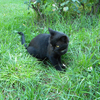

(Compressed KMean)


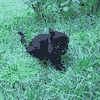

(Compressed Kmedoids)


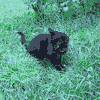

Photo number: 51 comparison:
(Original)


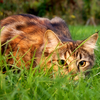

(Compressed KMean)


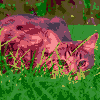

(Compressed Kmedoids)


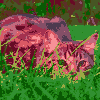

Photo number: 30 comparison:
(Original)


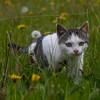

(Compressed KMean)


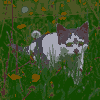

(Compressed Kmedoids)


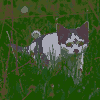

Photo number: 48 comparison:
(Original)


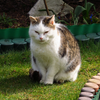

(Compressed KMean)


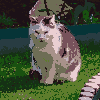

(Compressed Kmedoids)


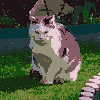

Photo number: 17 comparison:
(Original)


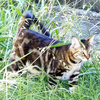

(Compressed KMean)


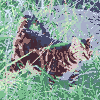

(Compressed Kmedoids)


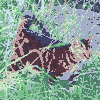

In [13]:
medoid_mdl = KMedoids(n_clusters=CLUSTER_NUM, init='k-medoids++', random_state=RANDOM_SEED)
warnings.filterwarnings('ignore', category=FutureWarning)

for i in np.random.choice(range(LEN_KITT), size=5, replace=False):
    print(f"Photo number: {i} comparison:")
    print("(Original)")
    print_kitty_picture(pixels_df, i)
    print("(Compressed KMean)") 
    print_kitty_picture(compressed_df, i)
    print("(Compressed Kmedoids)")

    # For KMedoids, we need to do compression again
    mask = (pixels_df['IsKitty'] == True) & (pixels_df['Photo'] == i)
    photo_medoids = pixels_df[mask].copy()
    photo_medoids[['H', 'L', 'S']] = compress_single(photo_medoids, medoid_mdl)
    photo_medoids[['R', 'G', 'B']] = rgb_from_hls(photo_medoids)
    
    print_kitty_picture(photo_medoids, i)  

Poieważ już posiadamy zbiór skompresowanych zdjęć, dla porządku pozbywamy się przeskalowanych kolumn używanych w klasterowaniu.

In [14]:
pixels_df = pixels_df.drop(columns=["LScaled", "SScaled", "CosH", "SinH"])
compressed_df = compressed_df.drop(columns=["LScaled", "SScaled", "CosH", "SinH"])

## Zadanie 4

Zapisujemy skompresowane zdjęcia, aby móc policzyć zysk z kompresji naszą metodą:

In [15]:
def save_photo(photo_df, name, size):
    image_pixels = photo_df.sort_values(by=["Y", "X"])
    image = Image.fromarray(image_pixels[["R", "G", "B"]].values.reshape(size, size, 3).astype(np.uint8))
    image.save(name)

FOLDER_NAME = "compressed_photos"
os.makedirs(FOLDER_NAME, exist_ok=True)
for iskitty in [True, False]:
    for photo in range(LEN_KITT if iskitty else LEN_FLOW):
        mask = (compressed_df["IsKitty"] == iskitty) & (compressed_df["Photo"] == photo)
        view = compressed_df[mask]
        save_photo(view, f"{FOLDER_NAME}/c{'kotek' if iskitty else 'kwiatek'}-{photo}.png", IMAGE_SIZE)

Tworzymy bazę danych obrazów i ich rozmiarów oraz unikatowch pikseli, by na jej podstawie móc przeprowadzić regresję liniową.

In [16]:
def get_file_sizes(folder_path):
    file_sizes = {}
    with os.scandir(folder_path) as entries:
        for entry in entries:
            if entry.is_file():
                file_sizes[entry.name] = entry.stat().st_size
    return file_sizes

normal_sizes = get_file_sizes("photos")
compressed_sizes = get_file_sizes("compressed_photos")
sizes_df = pd.DataFrame([
    [i, 
     p,
     normal_sizes[f"kotek-{p}.png" if i else f"kwiatek-{p}.png"], 
     compressed_sizes[f"ckotek-{p}.png" if i else f"ckwiatek-{p}.png"],
     px
     ] for i, p, px in pix_count_df[["IsKitty", "Photo", "PixelCount"]].values]
    , columns=["IsKitty", "Photo", "Size", "ReducedSize", "PxCount"])
sizes_df["Gain%"] = 100 * (sizes_df["Size"] - sizes_df["ReducedSize"]) / sizes_df["Size"]


Testy jak dopasowana jest regresja liniowa. Próbujemy dopasować kształty do:

1. Funkcji liniowej
2. Funkcji kwadratowej
3. Funckji sześciennej
4. Logarytmu
5. Pierwiastka
6. Odwrotnej zależności

In [17]:
from sklearn.linear_model import LinearRegression


best_score = -1
best_shape = None
rawX = sizes_df['PxCount']
Y = sizes_df['Gain%']

for form in ['linear', 'quadratic', 'log', 'sqrt', 'inverse', 'cubic']:
    if form == 'linear':
        X = rawX.values.reshape(-1, 1)
    elif form == 'quadratic':
        X = np.column_stack((rawX, rawX ** 2))
    elif form == 'log':
        X = np.log(rawX).values.reshape(-1, 1)
    elif form == 'sqrt':
        X = np.sqrt(rawX).values.reshape(-1, 1)
    elif form == 'inverse':
        X = (1 / rawX).values.reshape(-1, 1)
    elif form == 'cubic':
        X = np.column_stack((rawX, rawX ** 2, rawX ** 3))

    score = LinearRegression().fit(X, Y).score(X, Y)
    if score > best_score:
        best_score = score
        best_shape = form

print(f"Best transformation: {best_shape}")
print(f"Achived score of:  {best_score:.4f}")

Best transformation: cubic
Achived score of:  0.1142


Osiągnięty najlepszy wynik jest bardzo niski i osiągnięty przez model który najlepiej dopasowywałby się do losowego szumu. Na podstawie tego zakładamy, że obie kolumny są ze sobą bardzo słabo skorelowane. Obejrzmy je na wykresie, spójrzmy na coef_ dopasowania:

In [18]:
fig = px.scatter(sizes_df, x='PxCount', y='Gain%', title='Gain% vs Pixel Count')
fig.show()

X = sizes_df['PxCount']
X = np.column_stack((X, X ** 2, X ** 3))
Y = sizes_df['Gain%']
model = LinearRegression().fit(X, Y)
print(f"Achived coefficients: {model.coef_}")

Achived coefficients: [-9.67885328e-02  1.44294760e-05 -6.83411483e-10]


### Zależność zysku procentowego i ilości pikseli - podsumowanie

Na wykresie bardzo ciężko znaleźć sensowną korelację danych - większość wyników skupia się w klastrze w centrum około pxCount = 9500 i gain = 70%. Potwierdzają to też współczynniki regresji, nasz wielomian próbując się dopasować dobrał współczynniki bliskie zeru, wskazujące na lekko pozytywną, liniową zależność. Nie ma zatem podstawy przypuszczać, że zmienna zysku jest objaśniana przez ilość unikalnych pikseli.

## Zadanie 5

### Klasyfikacja binarna zdjęć kotów i kwiatów.

Wpierw przygotowujemy dane zgodnie z zaleceniami. Aby upakować zmienne HLS do jednej kolumny w prosty sposób, przeliczamy ile procent maksymalnej wartości one osiągają. Następnie zaokrąglamy te procenty do liczby całkowitej i "sklejamy" w jedną liczbę.

Potem dokonujemy pivota, w którym nowymi indexami wierszy są zdjęcia a kolumny są kolejnymi pikselami.

In [19]:
from sklearn.model_selection import train_test_split

# preparing bonding indexes together
def merge_HLS(hls_df):
    new_H = (hls_df["H"] / 360.0 * 100).round().astype(int) * 10000
    new_L = (hls_df["L"] * 100).round().astype(int) * 100
    new_S = (hls_df["S"] * 100).round().astype(int)
    return new_H + new_L + new_S

def widen_df(df):
    df["FlatXY"] = df['Y'] * 100 + df['X']
    matrix = df.pivot(index=['Photo', 'IsKitty'], columns='FlatXY', values='encodedhls')
    matrix = matrix.sort_index()
    df = df.drop(columns=["FlatXY"])
    return matrix

pixels_df["encodedhls"] = merge_HLS(pixels_df[["H", "L", "S"]])
wide_orig_df = widen_df(pixels_df)
compressed_df["encodedhls"] = merge_HLS(compressed_df[["H", "L", "S"]])
wide_comp_df = widen_df(compressed_df)

Teraz dokonujemy podziału na zbiór trenigowy i testowy. Podział dokonujemy wpierw na etykietach, aby zbiór oryginalny i po kompresji był podzielony na te same zdjęcia.

In [20]:
# preparing the splitting using ids
photo_ids = wide_orig_df.index
train_ids, test_ids = train_test_split(photo_ids, test_size=0.1, random_state=42, stratify=[i[1] for i in photo_ids])

# making the split
train_orig = wide_orig_df.loc[train_ids].values
train_comp = wide_comp_df.loc[train_ids].values
test_orig = wide_orig_df.loc[test_ids].values
test_comp = wide_comp_df.loc[test_ids].values
y_train = np.array([i[1] for i in train_ids]).astype(int)
y_test = np.array([i[1] for i in test_ids]).astype(int)

### Poszukiwanie dobrych wartości KNN.

W przypadku modeli kNN możemy dobierać przede wszystkim wartość k - ilość sąsiadów. Poza tym ważny jest również sposób liczenia wag sąsiadów (uniform, distance), oraz sposób liczenia odległości między punktami. Z sporej ilości metryk zdecydowałem się na testowanie euklidesowej, manhattan oraz cosine. Do szukania optymalnych parametrów wykorzystałem narzędzie optuna.

Podczas testowania ważne było zapewnienie, żeby wszystkie modele dla których testujemy wynik uzyskany poprzez walidację krzyżową, korzystały z identycznego splitu danych. Inaczej któreś kombinacje hiperparametrów mogłyby dostać cięższe zbiory testowe, co zaburzyłoby sprawiedliwe ocenienie wyników.

In [24]:
import optuna as opt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_score, StratifiedKFold

N_TRIALS = 100
MAX_NEIGHS = 15
CROSS_VAL = 5

fold_maker = StratifiedKFold(n_splits=CROSS_VAL, shuffle=True, random_state=RANDOM_SEED)
def objective(trial, X, Y):
    # Creating model for this trial.
    n_neighbors = trial.suggest_int('n_neighbors', 1, MAX_NEIGHS)
    metric = trial.suggest_categorical('metric', ['euclidean', 'manhattan', 'cosine'])
    weights = trial.suggest_categorical('weights', ['uniform', 'distance'])
    model = KNeighborsClassifier(n_neighbors=n_neighbors, metric=metric, weights=weights)

    # Passing fold_maker to ensure that the same splits are used for every trial.
    scores = cross_val_score(model, X, Y, cv=fold_maker, scoring='f1_macro')
    return np.mean(scores)

# mute logging every iteration from optuna
opt.logging.set_verbosity(opt.logging.WARNING)
print()

print("Finding best hyperparameters for kNN on original data...")
study_orig = opt.create_study(direction='maximize')
study_orig.optimize(lambda trial: objective(trial, train_orig, y_train), n_trials=N_TRIALS, show_progress_bar=True)

print("Finding best hyperparameters for kNN on compressed data...")
study_comp = opt.create_study(direction='maximize')
study_comp.optimize(lambda trial: objective(trial, train_comp, y_train), n_trials=N_TRIALS, show_progress_bar=True)

print(f"Best hyperparameters for original data: {study_orig.best_params}, f1 score of: {study_orig.best_value:.4f}")
print(f"Best hyperparameters for compressed data: {study_comp.best_params}, f1 score of: {study_comp.best_value:.4f}")


Finding best hyperparameters for kNN on original data...


Best trial: 14. Best value: 0.664984: 100%|██████████| 100/100 [00:05<00:00, 19.69it/s]


Finding best hyperparameters for kNN on compressed data...


Best trial: 22. Best value: 0.652042: 100%|██████████| 100/100 [00:04<00:00, 20.77it/s]

Best hyperparameters for original data: {'n_neighbors': 5, 'metric': 'manhattan', 'weights': 'uniform'}, f1 score of: 0.6650
Best hyperparameters for compressed data: {'n_neighbors': 8, 'metric': 'manhattan', 'weights': 'uniform'}, f1 score of: 0.6520


### Hiperparametry

Widzmy, że optuna dla obu zbiorów danych zdecydowała się na zastosowanie miary manhattan. Różnice w parametrach n_neighbors i weights z kolei na to, że dla skompresowanych danych lepiej zachowuje się ogólniejszy model, z wyższym biasem i niższą wariancją.

Przeanalizujmy zachowania naszych modeli jeszcze raz na obu zbiorach walidacji krzyżowej oraz przeproadźmy finałową konkluzję na zbiorze testowym.

In [25]:
orig_predictor = KNeighborsClassifier(**study_orig.best_params)
comp_predictor = KNeighborsClassifier(**study_comp.best_params)

def pretty_scores(scores):
    str = ""
    for sc in scores:
        str += f"{sc:.4f} "
    return str

def get_scores(model, X, Y):
    score_train = []
    score_test = []
    for train_idx, test_idx in fold_maker.split(X, Y):
        model.fit(X[train_idx], Y[train_idx])
        predtrain = model.predict(X[train_idx])
        predtest = model.predict(X[test_idx])

        stest = f1_score(Y[test_idx], predtest, average='macro')
        strain = f1_score(Y[train_idx], predtrain, average='macro')

        score_train.append(strain)
        score_test.append(stest)
    
    return score_train, score_test

print("Results of evaluating on training sets and validation sets...\n")

print("For original data:")
orig_train, orig_val = get_scores(orig_predictor, train_orig, y_train)
print(f"Training set results: {pretty_scores(orig_train)} - mean: {np.mean(orig_train):.4f} - std: {np.std(orig_train):.4f}")
print(f"Validation set results: {pretty_scores(orig_val)} - mean: {np.mean(orig_val):.4f} - std: {np.std(orig_val):.4f}")

print("\nFor compressed data:")
comp_train, comp_val = get_scores(comp_predictor, train_comp, y_train)
print(f"Training set results: {pretty_scores(comp_train)} - mean: {np.mean(comp_train):.4f} - std: {np.std(comp_train):.4f}")
print(f"Validation set results: {pretty_scores(comp_val)} - mean: {np.mean(comp_val):.4f} - std: {np.std(comp_val):.4f}")

print("\nResults of evaluating on test set...")
orig_score = f1_score(y_test, orig_predictor.fit(train_orig, y_train).predict(test_orig), average='macro')
comp_score = f1_score(y_test, comp_predictor.fit(train_comp, y_train).predict(test_comp), average='macro')
print(f"Original data kNN F1 Score: {orig_score:.4f}")
print(f"Compressed data kNN F1 Score: {comp_score:.4f}")

Results of evaluating on training sets and validation sets...

For original data:
Training set results: 0.7338 0.6795 0.6596 0.6622 0.7364  - mean: 0.6943 - std: 0.0340
Validation set results: 0.7037 0.7078 0.7913 0.5577 0.5644  - mean: 0.6650 - std: 0.0905

For compressed data:
Training set results: 0.7540 0.7125 0.6915 0.6520 0.7578  - mean: 0.7135 - std: 0.0397
Validation set results: 0.6571 0.7037 0.7500 0.5437 0.6057  - mean: 0.6520 - std: 0.0724

Results of evaluating on test set...
Original data kNN F1 Score: 0.8571
Compressed data kNN F1 Score: 0.6410


### Konkluzja wyników

Moim zdaniem zastosowanie kompresji nie pogorszyło jakości dopasowania metodą kNN, a przynajmniej nie mamy wystarczającego zbioru danych, by móc to stwierdzić. Ponieważ, analizuąc kolejno zbiory:

1. Testowy: Nie świadczy on o jakości modelu, ponadto dużo wyższe wyniki dla modelu oryginalnego są naturalnie spowodowane tym, że ma on niższą wartość k, więc jest w stanie dużo lepiej dopasować się do danych, kosztem utraty ogólności.

2. Walidacyjny: Na nich oba modele osiągają bardzo podobne wyniki. Strata 3% celności jest akceptowalna, tymbardziej że idzie w parze z mniejszą wariancją wyników.

3. Testowy: Ponieważ dla oryginalnych danych osiągnęliśmy wynik podejrzanie wysoki, znacznie wyższy od walidacyjnego, nie wyciągamy na jego podstawie wniosków. Z racji, że zbiór testowy jest małego rozmiaru, zapewne model miał po prostu sporo "szczęścia". Dla skompresowanych danych osiągnęliśmy zadowalający wynik na poziomie zbioru walidacyjnego.

Stąd widać, że nasz model kNN radzi sobie bardzo podobnie na obu typach danych: oryginalnych i skompresowanych - co więcej bez większego zbioru danych nie sposób realistycznie porównać oba modele - dla innego ziarna losowego algorytmów dzielących zbiór na próbki, np. 2138, jesteśmy w stanie osiągnąć wyniki przeważające szalę w przeciwną stronę. 